## Christian Yanez

In [1]:
#imports necessary for the project, taken from lecture and others required after online research
import numpy as np
import warnings
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.model_selection import (
    train_test_split, GridSearchCV, cross_val_score, 
    validation_curve, learning_curve
)
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix, 
    mean_squared_error, mean_absolute_error, r2_score, make_scorer, accuracy_score
)
from sklearn.datasets import fetch_openml
import seaborn as sns
import time
warnings.filterwarnings("default")
DF =  pd.read_csv('reduced_hitters.csv')
train_data = pd.read_csv('train_reduced.csv')
test_data = pd.read_csv('test_reduced.csv')

new_train_data = pd.read_csv('new_train_reduced.csv')
new_test_data = pd.read_csv('new_test_reduced.csv')
#I had to reduce some features for the sake of better performance.
#AtBat, Hits, HmRun, Runs, RBI, Walks, Years, Assists, Errors, League, NewLeague, Division, Salary

#the train data is 80% of the DF, test is 20%

train_data = new_train_data.dropna(subset=['Salary'])
test_data = new_test_data.dropna(subset=['Salary'])

# Separate features and target
X_train = train_data.drop('Salary', axis=1)
y_train = train_data['Salary'].values

X_test = test_data.drop('Salary', axis=1)
y_test = test_data['Salary'].values
# Convert categorical variables into dummy variables
X_train = pd.get_dummies(X_train)
X_test = pd.get_dummies(X_test)
X_train, X_test = X_train.align(
    X_test,
    join='left',
    axis=1,
    fill_value=0
)

## Neural Network

-------
Number of features: 4

Best parameters:
{'hidden_layer_sizes': (10,), 'learning_rate_init': 0.001}

Best CV R^2:
0.11119097348877338

Training R^2:
0.21716807711766528

Testing R^2:
0.3355809556516478

Tuning time:
33.315552949905396 seconds
-------
Number of features: 8

Best parameters:
{'hidden_layer_sizes': (10,), 'learning_rate_init': 0.001}

Best CV R^2:
0.14720924507576236

Training R^2:
0.48308055807992245

Testing R^2:
0.5811557598906132

Tuning time:
16.400249004364014 seconds
-------
Number of features: 15

Best parameters:
{'hidden_layer_sizes': (50,), 'learning_rate_init': 0.001}

Best CV R^2:
0.04756004360017037

Training R^2:
0.5710768009725875

Testing R^2:
0.5898345723176703

Tuning time:
10.915953874588013 seconds
Neural Network Results
   Number of Features  Tuning Time  Train R^2  Test R^2
0                   4    33.315553   0.217168  0.335581
1                   8    16.400249   0.483081  0.581156
2                  15    10.915954   0.571077  0.589835


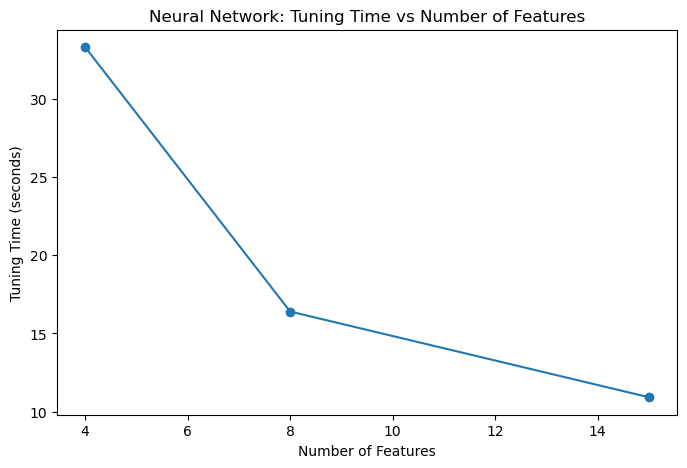

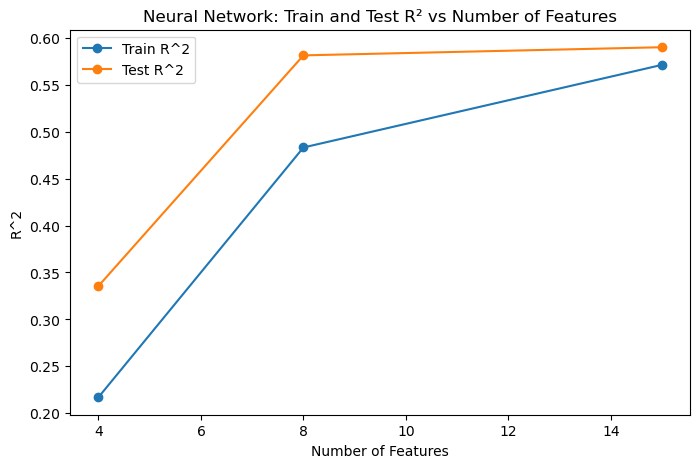

In [2]:
feature_sets = [
    list(X_train.columns[:4]),
    list(X_train.columns[:8]),
    list(X_train.columns)
]

feature_counts = []
tuning_times = []
train_r2_values = []
test_r2_values = []

for features in feature_sets:
    print("-------")
    print("Number of features:", len(features))
    X_train_subset = X_train[features]
    X_test_subset = X_test[features]
    scaler = StandardScaler()

    X_train_scaled = scaler.fit_transform(X_train_subset)
    X_test_scaled = scaler.transform(X_test_subset)


    mlp = MLPRegressor(
        activation='relu',
        solver='adam',
        alpha=0.001,
        max_iter=200000,#I had to increase the max iterations due to convergence warnings
        random_state=42
    )

    param_grid = {
        'hidden_layer_sizes': [(10,), (25,), (50,), (100,), (100, 50)],
        'learning_rate_init': [0.001,0.01]
    }

    grid_mlp = GridSearchCV(
        mlp,
        param_grid,
        cv=5,
        scoring='r2',
        n_jobs=-1
    )

    #hyperparameter tuning

    start_time = time.time()
    grid_mlp.fit(X_train_scaled,y_train)
    end_time = time.time()
    tuning_time = end_time - start_time

    # Best neural network

    best_mlp = grid_mlp.best_estimator_

    # Predictions
    y_train_pred = best_mlp.predict(X_train_scaled)
    y_test_pred = best_mlp.predict(X_test_scaled)

    # Calculate R^2
    train_r2 = r2_score(y_train, y_train_pred)
    test_r2 = r2_score(y_test, y_test_pred)

    # Store results
    feature_counts.append(len(features))
    tuning_times.append(tuning_time)
    train_r2_values.append(train_r2)
    test_r2_values.append(test_r2)

    # Display results
    print("\nBest parameters:")
    print(grid_mlp.best_params_)

    print("\nBest CV R^2:")
    print(grid_mlp.best_score_)

    print("\nTraining R^2:")
    print(train_r2)

    print("\nTesting R^2:")
    print(test_r2)

    print("\nTuning time:")
    print(tuning_time, "seconds")

# Create results DataFrame

nn_results = pd.DataFrame({
    'Number of Features': feature_counts,
    'Tuning Time': tuning_times,
    'Train R^2': train_r2_values,
    'Test R^2': test_r2_values
})

print("Neural Network Results")

print(nn_results)

# Plot 1: Time Spent vs # of Features
plt.figure(figsize=(8, 5))

plt.plot(
    feature_counts,
    tuning_times,
    marker='o'
)

plt.xlabel('Number of Features')
plt.ylabel('Tuning Time (seconds)')
plt.title('Neural Network: Tuning Time vs Number of Features')

plt.show()

# Plot 2: Train and Test R² vs # of Features
plt.figure(figsize=(8, 5))

plt.plot(
    feature_counts,
    train_r2_values,
    marker='o',
    label='Train R^2'
)

plt.plot(
    feature_counts,
    test_r2_values,
    marker='o',
    label='Test R^2'
)

plt.xlabel('Number of Features')
plt.ylabel('R^2')
plt.title('Neural Network: Train and Test R² vs Number of Features')
plt.legend()
plt.show()

Calculate Bias Variance(number of weights)

I added this after the initial 2 graphs and decided to restart the information

And then just copy the pre-established functions

But it uses all of the features at once, and not the nested feature set used before

-------
neurons in layers: (10,)

Number of weights:
160

Training R^2:
0.49672889191625913

Testing R^2:
0.5869688674192424
-------
neurons in layers: (25,)

Number of weights:
400

Training R^2:
0.6008972150736609

Testing R^2:
0.5998866042193038
-------
neurons in layers: (50,)

Number of weights:
800

Training R^2:
0.5710768009725875

Testing R^2:
0.5898345723176703
-------
neurons in layers: (100,)

Number of weights:
1600

Training R^2:
0.5363582836992938

Testing R^2:
0.6161336625649938
-------
neurons in layers: (100, 50)

Number of weights:
6550

Training R^2:
0.44562409109633405

Testing R^2:
0.5626366453879791
Neural network bias variance
      Neuron  Number of Weights  Train R^2  Test R^2
0      (10,)                160   0.496729  0.586969
1      (25,)                400   0.600897  0.599887
2      (50,)                800   0.571077  0.589835
3     (100,)               1600   0.536358  0.616134
4  (100, 50)               6550   0.445624  0.562637


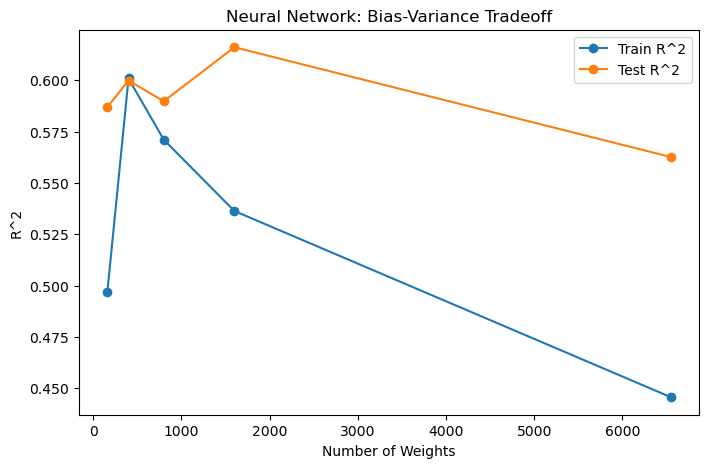

In [3]:
neurons = [(10,), (25,), (50,), (100,), (100, 50)]

number_of_weights = []
nn_train_r2 = []
nn_test_r2 = []

X_train_subset = X_train
X_test_subset = X_test

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_subset)
X_test_scaled = scaler.transform(X_test_subset)

for neuron in neurons:

    print("-------")
    print("neurons in layers:", neuron)

    mlp = MLPRegressor(
        hidden_layer_sizes=neuron,
        activation='relu',
        solver='adam',
        alpha=0.001,
        learning_rate_init=0.001,
        max_iter=20000,
        random_state=42
    )

    mlp.fit(X_train_scaled, y_train)

    # Calculate the total number of weights
    total_weights = 0

    for weights in mlp.coefs_:
        total_weights += weights.size

    y_train_pred = mlp.predict(X_train_scaled)
    y_test_pred = mlp.predict(X_test_scaled)

    train_r2 = r2_score(y_train,y_train_pred)
    test_r2 = r2_score(y_test, y_test_pred)

    # Store results
    number_of_weights.append(total_weights)
    nn_train_r2.append(train_r2)
    nn_test_r2.append(test_r2)

    print("\nNumber of weights:")
    print(total_weights)

    print("\nTraining R^2:")
    print(train_r2)

    print("\nTesting R^2:")
    print(test_r2)

# Create results DataFrame

nn_bias_variance_results = pd.DataFrame({
    'Neuron': neurons,
    'Number of Weights': number_of_weights,
    'Train R^2': nn_train_r2,
    'Test R^2': nn_test_r2
})

print("Neural network bias variance")
print(nn_bias_variance_results)

# Plot: Train and Test R² vs Number of Weights

plt.figure(figsize=(8, 5))

plt.plot(
    number_of_weights,
    nn_train_r2,
    marker='o',
    label='Train R^2'
)

plt.plot(
    number_of_weights,
    nn_test_r2,
    marker='o',
    label='Test R^2'
)

plt.xlabel('Number of Weights')
plt.ylabel('R^2')
plt.title('Neural Network: Bias-Variance Tradeoff')
plt.legend()
plt.show()

## KNN

-------
Number of features: 4

Best parameters:
{'knn__n_neighbors': 50, 'knn__weights': 'uniform'}

Best CV R^2:
0.1696899001225267

Training R^2:
0.19897848721592248

Testing R^2:
0.21924929367682255

Tuning time:
0.18279695510864258 seconds
-------
Number of features: 8

Best parameters:
{'knn__n_neighbors': 15, 'knn__weights': 'uniform'}

Best CV R^2:
0.3590457039285339

Training R^2:
0.4392637871811198

Testing R^2:
0.44167011244742094

Tuning time:
0.03849601745605469 seconds
-------
Number of features: 15

Best parameters:
{'knn__n_neighbors': 10, 'knn__weights': 'uniform'}

Best CV R^2:
0.28170461215657616

Training R^2:
0.41823825782436896

Testing R^2:
0.4046444652055087

Tuning time:
0.03899693489074707 seconds
KNN regression results
   Number of Features  Tuning Time  Train R^2  Test R^2
0                   4     0.182797   0.198978  0.219249
1                   8     0.038496   0.439264  0.441670
2                  15     0.038997   0.418238  0.404644


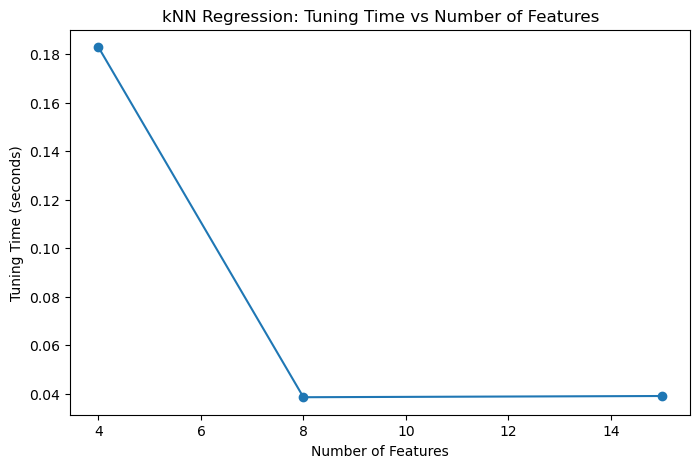

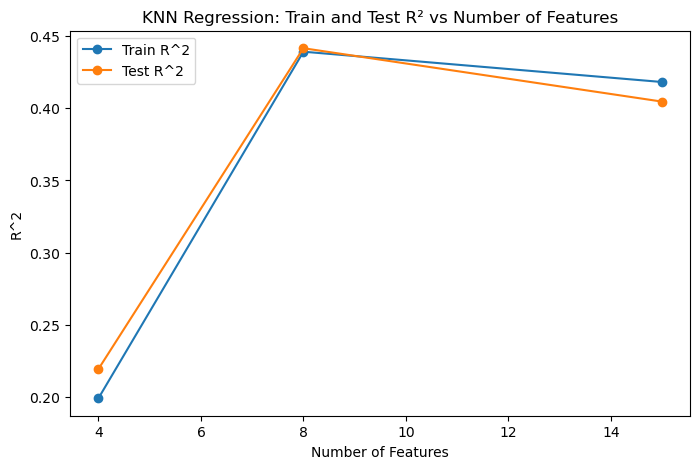

In [4]:
from sklearn.neighbors import KNeighborsRegressor
feature_sets = [
    list(X_train.columns[:4]),
    list(X_train.columns[:8]),
    list(X_train.columns)
]

feature_counts = []
tuning_times = []
train_r2_values = []
test_r2_values = []

for features in feature_sets:
    print("-------")
    print("Number of features:", len(features))

    X_train_subset = X_train[features]
    X_test_subset = X_test[features]

    knn_pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('knn', KNeighborsRegressor())
    ])

    param_grid = {
        'knn__n_neighbors': [1, 5, 10, 15, 20, 30, 40, 50, 100],
        'knn__weights': ['uniform']
    }

    grid_knn = GridSearchCV(
        knn_pipeline,
        param_grid,
        cv=5,
        scoring='r2',
        n_jobs=-1
    )

    start_time = time.time()
    grid_knn.fit(X_train_subset, y_train)
    end_time = time.time()

    tuning_time = end_time - start_time

    best_knn = grid_knn.best_estimator_

    y_train_pred = best_knn.predict(X_train_subset)
    y_test_pred = best_knn.predict(X_test_subset)

    train_r2 = r2_score(y_train, y_train_pred)
    test_r2 = r2_score(y_test, y_test_pred)

    feature_counts.append(len(features))
    tuning_times.append(tuning_time)
    train_r2_values.append(train_r2)
    test_r2_values.append(test_r2)

    print("\nBest parameters:")
    print(grid_knn.best_params_)
    print("\nBest CV R^2:")
    print(grid_knn.best_score_)
    print("\nTraining R^2:")
    print(train_r2)
    print("\nTesting R^2:")
    print(test_r2)
    print("\nTuning time:")
    print(tuning_time, "seconds")

knn_results = pd.DataFrame({
    'Number of Features': feature_counts,
    'Tuning Time': tuning_times,
    'Train R^2': train_r2_values,
    'Test R^2': test_r2_values
})

print("KNN regression results")
print(knn_results)

plt.figure(figsize=(8, 5))
plt.plot(feature_counts, tuning_times, marker='o')
plt.xlabel('Number of Features')
plt.ylabel('Tuning Time (seconds)')
plt.title('kNN Regression: Tuning Time vs Number of Features')
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(feature_counts, train_r2_values, marker='o', label='Train R^2')
plt.plot(feature_counts, test_r2_values, marker='o', label='Test R^2')
plt.xlabel('Number of Features')
plt.ylabel('R^2')
plt.title('KNN Regression: Train and Test R² vs Number of Features')
plt.legend()
plt.show()

Bias Variance for KNN

-------
Number of neighbors: 1

Training R^2:
1.0

Testing R^2:
0.08740505883289196
-------
Number of neighbors: 5

Training R^2:
0.530607912276464

Testing R^2:
0.2761586426184022
-------
Number of neighbors: 10

Training R^2:
0.41823825782436896

Testing R^2:
0.4046444652055087
-------
Number of neighbors: 15

Training R^2:
0.3756610442855135

Testing R^2:
0.3768616811808986
-------
Number of neighbors: 20

Training R^2:
0.34703812035018555

Testing R^2:
0.37588240167081133
-------
Number of neighbors: 30

Training R^2:
0.31405168386942584

Testing R^2:
0.30889329258319687
-------
Number of neighbors: 40

Training R^2:
0.29567891848953565

Testing R^2:
0.30954821826817547
-------
Number of neighbors: 50

Training R^2:
0.28095160628012283

Testing R^2:
0.3102901937186898
KNN bias variance results
   n_neighbors  Train R^2  Test R^2
0            1   1.000000  0.087405
1            5   0.530608  0.276159
2           10   0.418238  0.404644
3           15   0.375661  0.376862
4          

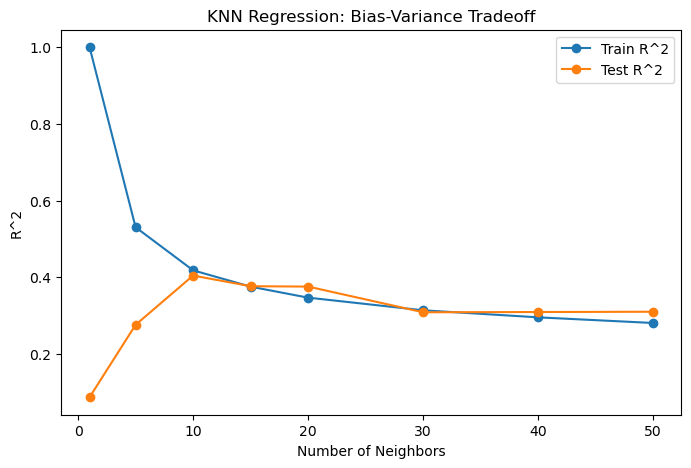

In [5]:
n_neighbors_values = [1, 5, 10, 15, 20, 30, 40, 50]
knn_train_r2 = []
knn_test_r2 = []

# Use all features for the bias-variance experiment
X_train_subset = X_train
X_test_subset = X_test

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_subset)
X_test_scaled = scaler.transform(X_test_subset)

for n_neighbors in n_neighbors_values:

    print("-------")
    print("Number of neighbors:", n_neighbors)

    knn = KNeighborsRegressor(
        n_neighbors=n_neighbors,
        weights='uniform',
        p=2
    )

    knn.fit(X_train_scaled, y_train)
    
    y_train_pred = knn.predict(X_train_scaled)
    y_test_pred = knn.predict(X_test_scaled)

    train_r2 = r2_score(y_train, y_train_pred)
    test_r2 = r2_score(y_test, y_test_pred)

    knn_train_r2.append(train_r2)
    knn_test_r2.append(test_r2)

    print("\nTraining R^2:")
    print(train_r2)

    print("\nTesting R^2:")
    print(test_r2)


# Create results DataFrame

knn_bias_variance_results = pd.DataFrame({
    'n_neighbors': n_neighbors_values,
    'Train R^2': knn_train_r2,
    'Test R^2': knn_test_r2
})

print("KNN bias variance results")

print(knn_bias_variance_results)

# Plot: Train and Test R² vs Number of Neighbors

plt.figure(figsize=(8, 5))
plt.plot(
    n_neighbors_values,
    knn_train_r2,
    marker='o',
    label='Train R^2'
)

plt.plot(
    n_neighbors_values,
    knn_test_r2,
    marker='o',
    label='Test R^2'
)

plt.xlabel('Number of Neighbors')
plt.ylabel('R^2')
plt.title('KNN Regression: Bias-Variance Tradeoff')
plt.legend()
plt.show()

## Kernel Ridge Regression

-------
Number of features: 4

Best parameters:
{'kernel__alpha': 1, 'kernel__gamma': 0.1}

Best CV R^2:
0.15160613160086034

Training R^2:
0.28997056279414646

Testing R^2:
0.13356118351551682

Tuning time:
0.07322025299072266 seconds
-------
Number of features: 8

Best parameters:
{'kernel__alpha': 1, 'kernel__gamma': 0.1}

Best CV R^2:
0.4104361317846905

Training R^2:
0.642721420104968

Testing R^2:
0.44586024750875997

Tuning time:
0.052564144134521484 seconds
-------
Number of features: 15

Best parameters:
{'kernel__alpha': 0.1, 'kernel__gamma': 0.01}

Best CV R^2:
0.388231078362563

Training R^2:
0.6024669430950627

Testing R^2:
0.5724763695871746

Tuning time:
0.054100990295410156 seconds
Kernel Ridge Regression Results
   Number of Features  Tuning Time  Train R^2  Test R^2
0                   4     0.073220   0.289971  0.133561
1                   8     0.052564   0.642721  0.445860
2                  15     0.054101   0.602467  0.572476


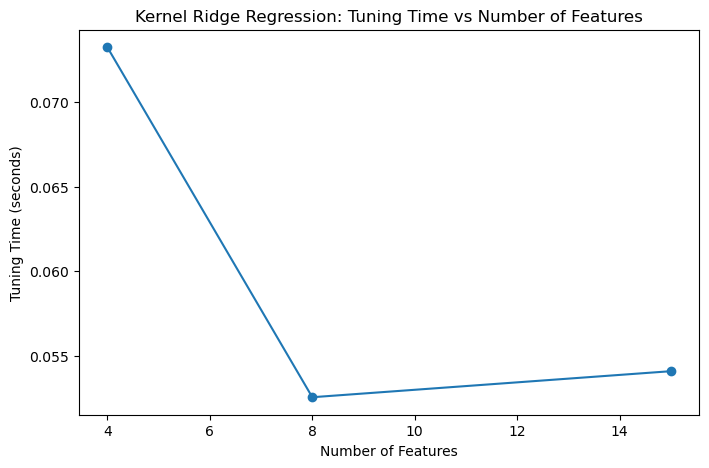

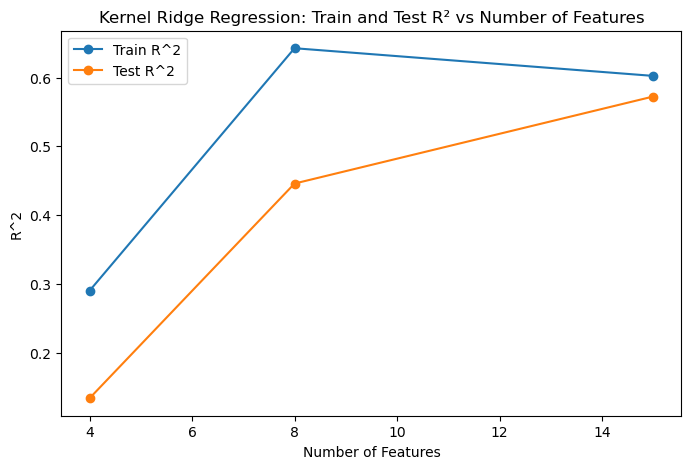

In [6]:
from sklearn.kernel_ridge import KernelRidge

feature_sets = [
    list(X_train.columns[:4]),
    list(X_train.columns[:8]),
    list(X_train.columns)
]

feature_counts = []
tuning_times = []
train_r2_values = []
test_r2_values = []

for features in feature_sets:
    print("-------")
    print("Number of features:", len(features))

    X_train_subset = X_train[features]
    X_test_subset = X_test[features]

    kernel_pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('kernel', KernelRidge(
            kernel='rbf'
        ))
    ])

    param_grid = {
        'kernel__alpha': [0.01, 0.1, 1, 10, 100],
        'kernel__gamma': [0.001, 0.01, 0.1, 0.5, 1]
    }

    grid_kernel = GridSearchCV(
        kernel_pipeline,
        param_grid,
        cv=5,
        scoring='r2',
        n_jobs=-1
    )

    # hyperparameter tuning

    start_time = time.time()
    grid_kernel.fit(X_train_subset, y_train)
    end_time = time.time()
    tuning_time = end_time - start_time

    # Best kernel regression model

    best_kernel = grid_kernel.best_estimator_

    y_train_pred = best_kernel.predict(X_train_subset)
    y_test_pred = best_kernel.predict(X_test_subset)

    train_r2 = r2_score(y_train, y_train_pred)
    test_r2 = r2_score(y_test, y_test_pred)

    feature_counts.append(len(features))
    tuning_times.append(tuning_time)
    train_r2_values.append(train_r2)
    test_r2_values.append(test_r2)

    # Display results
    print("\nBest parameters:")
    print(grid_kernel.best_params_)

    print("\nBest CV R^2:")
    print(grid_kernel.best_score_)

    print("\nTraining R^2:")
    print(train_r2)

    print("\nTesting R^2:")
    print(test_r2)

    print("\nTuning time:")
    print(tuning_time, "seconds")


# Create results DataFrame

kernel_results = pd.DataFrame({
    'Number of Features': feature_counts,
    'Tuning Time': tuning_times,
    'Train R^2': train_r2_values,
    'Test R^2': test_r2_values
})

print("Kernel Ridge Regression Results")

print(kernel_results)


# Time Spent vs # of Features

plt.figure(figsize=(8, 5))

plt.plot(
    feature_counts,
    tuning_times,
    marker='o'
)

plt.xlabel('Number of Features')
plt.ylabel('Tuning Time (seconds)')
plt.title('Kernel Ridge Regression: Tuning Time vs Number of Features')

plt.show()

# Train and Test R² vs # of Features

plt.figure(figsize=(8, 5))

plt.plot(
    feature_counts,
    train_r2_values,
    marker='o',
    label='Train R^2'
)

plt.plot(
    feature_counts,
    test_r2_values,
    marker='o',
    label='Test R^2'
)

plt.xlabel('Number of Features')
plt.ylabel('R^2')
plt.title('Kernel Ridge Regression: Train and Test R² vs Number of Features')
plt.legend()
plt.show()

Kernel Regression Bias Variance

-------
Alpha: 0.01
Training R^2: 0.7691024294440212
Testing R^2: 0.518486352168742
-------
Alpha: 0.1
Training R^2: 0.6024669430950627
Testing R^2: 0.5724763695871746
-------
Alpha: 1
Training R^2: 0.4414695098556275
Testing R^2: 0.4900415851085598
-------
Alpha: 10
Training R^2: 0.2384411229323754
Testing R^2: 0.23801688602205673
-------
Alpha: 100
Training R^2: -0.17367187775444903
Testing R^2: -0.25599526623300317
Kernel Ridge bias variance
    Alpha  Train R^2  Test R^2
0    0.01   0.769102  0.518486
1    0.10   0.602467  0.572476
2    1.00   0.441470  0.490042
3   10.00   0.238441  0.238017
4  100.00  -0.173672 -0.255995


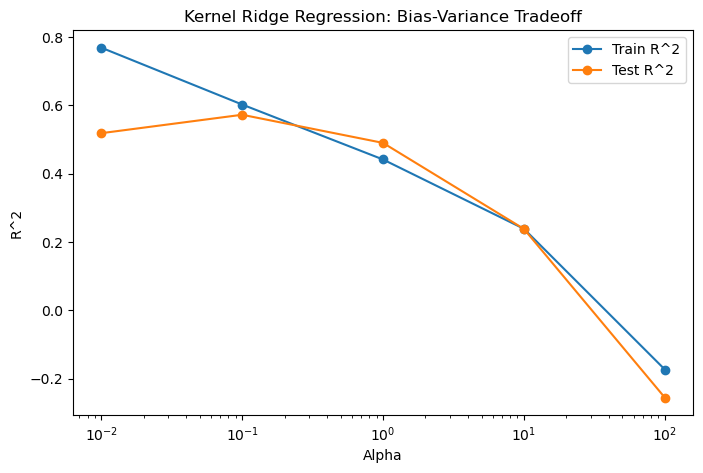

In [7]:
# Bias-Variance Tradeoff
#Cycle through the different alphas to show 
alpha_values = [0.01, 0.1, 1, 10, 100]

kernel_train_r2 = []
kernel_test_r2 = []

for alpha in alpha_values:
    print("-------")
    print("Alpha:", alpha)

    kernel = Pipeline([
        ('scaler', StandardScaler()),
        ('kernel', KernelRidge(
            kernel='rbf',
            alpha=alpha,
            gamma=0.01
        ))
    ])

    kernel.fit(X_train, y_train)

    y_train_pred = kernel.predict(X_train)
    y_test_pred = kernel.predict(X_test)

    train_r2 = r2_score(y_train, y_train_pred)
    test_r2 = r2_score(y_test, y_test_pred)

    kernel_train_r2.append(train_r2)
    kernel_test_r2.append(test_r2)

    print("Training R^2:", train_r2)
    print("Testing R^2:", test_r2)


kernel_bias_variance_results = pd.DataFrame({
    'Alpha': alpha_values,
    'Train R^2': kernel_train_r2,
    'Test R^2': kernel_test_r2
})

print("Kernel Ridge bias variance")

print(kernel_bias_variance_results)

# Bias-Variance Tradeoff Plot

plt.figure(figsize=(8, 5))

plt.plot(
    alpha_values,
    kernel_train_r2,
    marker='o',
    label='Train R^2'
)

plt.plot(
    alpha_values,
    kernel_test_r2,
    marker='o',
    label='Test R^2'
)

plt.xscale('log')

plt.xlabel('Alpha')
plt.ylabel('R^2')
plt.title('Kernel Ridge Regression: Bias-Variance Tradeoff')
plt.legend()
plt.show()

## SVM

-------
Number of features: 4

Best parameters:
{'C': 100}

Best CV R^2:
0.13192202943237852

Training R^2:
0.22979405783340967

Testing R^2:
0.06963658283246621

Tuning time:
0.06852889060974121 seconds
-------
Number of features: 8

Best parameters:
{'C': 1000}

Best CV R^2:
0.37802353030059394

Training R^2:
0.6963558697022632

Testing R^2:
0.5001008009367636

Tuning time:
0.060132741928100586 seconds
-------
Number of features: 15

Best parameters:
{'C': 1000}

Best CV R^2:
0.36547997246412844

Training R^2:
0.7063727534058425

Testing R^2:
0.4721181368968975

Tuning time:
0.028887033462524414 seconds
SVM results
   Number of Features  Tuning Time  Train R^2  Test R^2
0                   4     0.068529   0.229794  0.069637
1                   8     0.060133   0.696356  0.500101
2                  15     0.028887   0.706373  0.472118


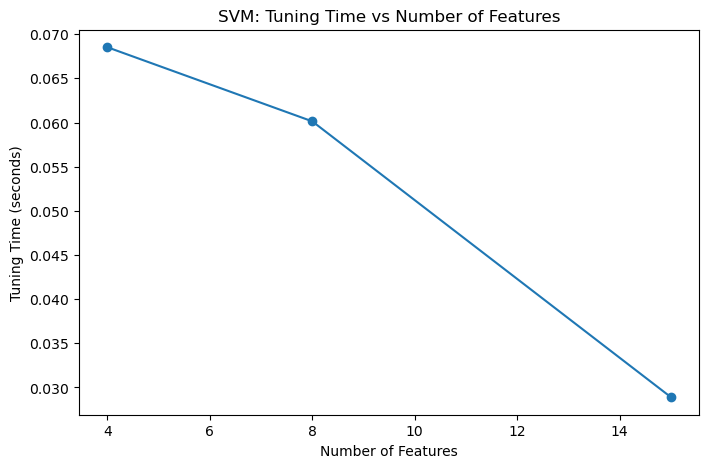

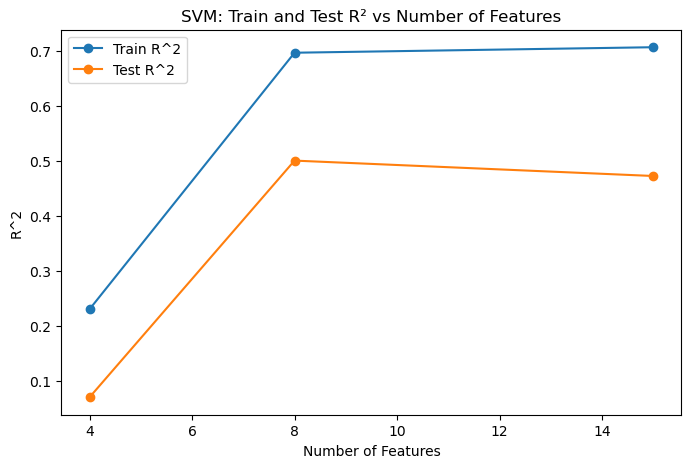

In [8]:
from sklearn.svm import SVR
feature_sets = [
    list(X_train.columns[:4]),
    list(X_train.columns[:8]),
    list(X_train.columns)
]

feature_counts = []
tuning_times = []
train_r2_values = []
test_r2_values = []

for features in feature_sets:
    print("-------")
    print("Number of features:", len(features))

    X_train_subset = X_train[features]
    X_test_subset = X_test[features]

    scaler = StandardScaler()

    X_train_scaled = scaler.fit_transform(X_train_subset)
    X_test_scaled = scaler.transform(X_test_subset)

    svr = SVR(
        kernel='rbf',
    )

    param_grid = {
        'C': [0.1, 1, 10,100, 1000, 10000, 100000]
    }

    grid_svr = GridSearchCV(
        svr,
        param_grid,
        cv=5,
        scoring='r2',
        n_jobs=-1
    )

    # hyperparameter tuning

    start_time = time.time()

    grid_svr.fit(
        X_train_scaled,
        y_train
    )

    end_time = time.time()

    tuning_time = end_time - start_time

    # Best support vector machine

    best_svr = grid_svr.best_estimator_

    y_train_pred = best_svr.predict(X_train_scaled)
    y_test_pred = best_svr.predict(X_test_scaled)

    train_r2 = r2_score(y_train, y_train_pred)
    test_r2 = r2_score(y_test, y_test_pred)

    feature_counts.append(len(features))
    tuning_times.append(tuning_time)
    train_r2_values.append(train_r2)
    test_r2_values.append(test_r2)

    print("\nBest parameters:")
    print(grid_svr.best_params_)

    print("\nBest CV R^2:")
    print(grid_svr.best_score_)

    print("\nTraining R^2:")
    print(train_r2)

    print("\nTesting R^2:")
    print(test_r2)

    print("\nTuning time:")
    print(tuning_time, "seconds")


# Create results DataFrame

svm_results = pd.DataFrame({
    'Number of Features': feature_counts,
    'Tuning Time': tuning_times,
    'Train R^2': train_r2_values,
    'Test R^2': test_r2_values
})

print("SVM results")

print(svm_results)

# Plot 1: Time Spent vs # of Features

plt.figure(figsize=(8, 5))

plt.plot(
    feature_counts,
    tuning_times,
    marker='o'
)

plt.xlabel('Number of Features')
plt.ylabel('Tuning Time (seconds)')
plt.title('SVM: Tuning Time vs Number of Features')
plt.show()

# Plot 2: Train and Test R² vs # of Features

plt.figure(figsize=(8, 5))

plt.plot(
    feature_counts,
    train_r2_values,
    marker='o',
    label='Train R^2'
)

plt.plot(
    feature_counts,
    test_r2_values,
    marker='o',
    label='Test R^2'
)

plt.xlabel('Number of Features')
plt.ylabel('R^2')
plt.title('SVM: Train and Test R² vs Number of Features')
plt.legend()
plt.show()

SVM Bias Variance

-------
C: 0.01

Training R^2:
-0.05347052061585811

Testing R^2:
-0.1089831317764538
-------
C: 0.1

Training R^2:
-0.05172141739488545

Testing R^2:
-0.10776205262253802
-------
C: 1

Training R^2:
-0.02787406899890943

Testing R^2:
-0.08718698705259009
-------
C: 10

Training R^2:
0.13187579343091382

Testing R^2:
0.0511946581344338
-------
C: 100

Training R^2:
0.4325918048200468

Testing R^2:
0.3038515505239948
-------
C: 1000

Training R^2:
0.7063727534058425

Testing R^2:
0.4721181368968975
-------
C: 10000

Training R^2:
0.9635112157094717

Testing R^2:
0.4080756442083755
-------
C: 100000

Training R^2:
0.999999948165748

Testing R^2:
0.12805931103418866
SVM bias variance results
           C  Train R^2  Test R^2
0       0.01  -0.053471 -0.108983
1       0.10  -0.051721 -0.107762
2       1.00  -0.027874 -0.087187
3      10.00   0.131876  0.051195
4     100.00   0.432592  0.303852
5    1000.00   0.706373  0.472118
6   10000.00   0.963511  0.408076
7  100000.00   1.000000  0.128

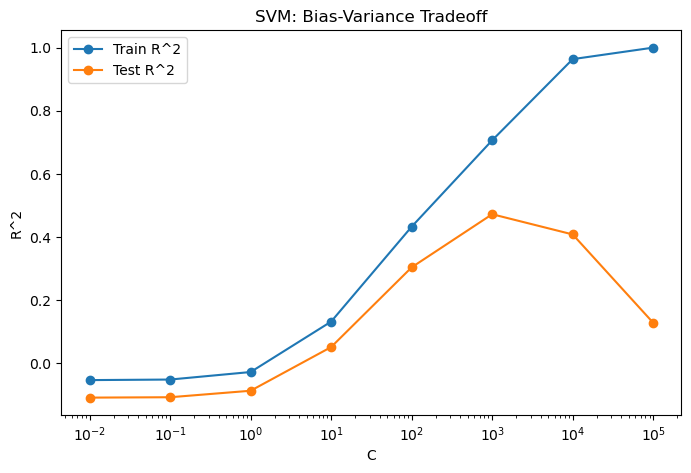

In [9]:
C_values = [0.01, 0.1, 1, 10, 100, 1000, 10000, 100000]

svm_train_r2 = []
svm_test_r2 = []

# Use all features for the bias-variance experiment
X_train_subset = X_train
X_test_subset = X_test

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_subset)
X_test_scaled = scaler.transform(X_test_subset)

for C in C_values:

    print("-------")
    print("C:", C)

    svr = SVR(
        kernel='rbf',
        C=C
    )

    svr.fit(X_train_scaled, y_train)

    y_train_pred = svr.predict(X_train_scaled)
    y_test_pred = svr.predict(X_test_scaled)

    train_r2 = r2_score(y_train, y_train_pred)
    test_r2 = r2_score(y_test, y_test_pred)

    svm_train_r2.append(train_r2)
    svm_test_r2.append(test_r2)

    print("\nTraining R^2:")
    print(train_r2)

    print("\nTesting R^2:")
    print(test_r2)


svm_bias_variance_results = pd.DataFrame({
    'C': C_values,
    'Train R^2': svm_train_r2,
    'Test R^2': svm_test_r2
})

print("SVM bias variance results")
print(svm_bias_variance_results)


plt.figure(figsize=(8, 5))

plt.plot(
    C_values,
    svm_train_r2,
    marker='o',
    label='Train R^2'
)

plt.plot(
    C_values,
    svm_test_r2,
    marker='o',
    label='Test R^2'
)

plt.xscale('log')
plt.xlabel('C')
plt.ylabel('R^2')
plt.title('SVM: Bias-Variance Tradeoff')
plt.legend()
plt.show()